In [1]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from dotenv import load_dotenv

In [2]:
load_dotenv()

True

In [3]:
class SubState(TypedDict):
    input_text: str
    translated_text: str

In [4]:
subgraph_llm = ChatGroq(model='openai/gpt-oss-120b')

In [5]:
def translate_text(state: SubState):

    prompt = f"""
    Translate the following text to Hindi.
    Keep it natural and clear. Do not add extra content.

    Text:
    {state["input_text"]}
    """.strip()
    
    translated_text = subgraph_llm.invoke(prompt).content

    return {'translated_text': translated_text}

In [6]:
subgraph_builder = StateGraph(SubState)

subgraph_builder.add_node('translate_text', translate_text)

subgraph_builder.add_edge(START, 'translate_text')
subgraph_builder.add_edge('translate_text', END)

subgraph = subgraph_builder.compile()

In [7]:
class ParentState(TypedDict):

    question: str
    answer_eng: str
    answer_hin: str

In [8]:
parent_llm  = ChatGroq(model='openai/gpt-oss-120b')

In [9]:
def generate_answer(state: ParentState):

    answer = parent_llm.invoke(f"You are a helpful assistant. Answer clearly.\n\nQuestion: {state['question']}").content
    return {'answer_eng': answer}

In [10]:
def translate_answer(state: ParentState):

    # call the subgraph
    result = subgraph.invoke({'input_text': state['answer_eng']})

    return {'answer_hin': result['translated_text']}

In [11]:
parent_builder = StateGraph(ParentState)

parent_builder.add_node("answer", generate_answer)
parent_builder.add_node("translate", translate_answer)

parent_builder.add_edge(START, 'answer')
parent_builder.add_edge('answer', 'translate')
parent_builder.add_edge('translate', END)

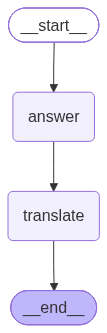

In [12]:
graph = parent_builder.compile()

graph

In [13]:
graph.invoke({'question': 'What is quantum physics'})

{'question': 'What is quantum physics',
 'answer_eng': '**Quantum physics** (also called quantum mechanics or quantum theory) is the branch of physics that describes how matter and energy behave on the smallest scales—typically at the level of atoms, electrons, photons, and other sub‑atomic particles. \n\n---\n\n## Core Ideas\n\n| Concept | What it means (in simple terms) | Why it matters |\n|---------|--------------------------------|----------------|\n| **Quantization** | Certain properties (energy, angular momentum, charge) can only take on discrete “chunks” or “quanta” rather than any value. | Explains why atoms have stable electron shells and why light can be emitted or absorbed as individual packets (photons). |\n| **Wave‑Particle Duality** | Particles such as electrons and photons exhibit both wave‑like and particle‑like behavior, depending on how you measure them. | Leads to phenomena like diffraction of electrons and the photoelectric effect. |\n| **Superposition** | A quantum